In [ ]:
# Import Required Libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

all_books = []

headers = {
    "User-Agent": "Mozilla/5.0"
}

for page in range(1, 51):

    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url, headers=headers, timeout=20)

    if response.status_code != 200:
        print(f"Stopped at page {page}. Status:", response.status_code)
        break

    soup = BeautifulSoup(response.text, "html.parser")
    books = soup.find_all("article", class_="product_pod")

    for book in books:

        name = book.h3.a.get("title", "").strip()
        price = book.find("p", class_="price_color").get_text(strip=True)
        rating = book.p.get("class", ["", "Unknown"])[1]

        availability = book.find(
            "p", class_="instock availability"
        ).get_text(" ", strip=True)

        book_link = book.h3.a.get("href", "")
        book_url = requests.compat.urljoin(url, book_link)

        category = "Unknown"

        try:
            book_response = requests.get(
                book_url, headers=headers, timeout=20
            )

            if book_response.status_code == 200:
                book_soup = BeautifulSoup(
                    book_response.text, "html.parser"
                )

                breadcrumb_items = [
                    li.get_text(" ", strip=True)
                    for li in book_soup.select("ul.breadcrumb li")
                ]

                if len(breadcrumb_items) >= 3:
                    category = breadcrumb_items[-2]
                    print(breadcrumb_items)

        except requests.RequestException:
            category = "Unknown"

        all_books.append({
            "Book_Name": name,
            "Category": category,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Page": page
        })

    print(f"Page {page}: {len(books)} books collected")

    time.sleep(0.2)

# Create the scraped DataFrame
scraped_df = pd.DataFrame(all_books)

print("\nScraping Completed!")
print("Total books scraped:", len(scraped_df))
print("Dataset shape:", scraped_df.shape)

display(scraped_df.head())


['Home', 'Books', 'Poetry', 'A Light in the Attic']
['Home', 'Books', 'Historical Fiction', 'Tipping the Velvet']
['Home', 'Books', 'Fiction', 'Soumission']
['Home', 'Books', 'Mystery', 'Sharp Objects']
['Home', 'Books', 'History', 'Sapiens: A Brief History of Humankind']
['Home', 'Books', 'Young Adult', 'The Requiem Red']
['Home', 'Books', 'Business', 'The Dirty Little Secrets of Getting Your Dream Job']
['Home', 'Books', 'Default', 'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull']
['Home', 'Books', 'Default', 'The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics']
['Home', 'Books', 'Poetry', 'The Black Maria']
['Home', 'Books', 'Default', 'Starving Hearts (Triangular Trade Trilogy, #1)']
['Home', 'Books', 'Poetry', "Shakespeare's Sonnets"]
['Home', 'Books', 'Young Adult', 'Set Me Free']
['Home', 'Books', 'Sequential Art', "Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)"]
['Home', 'Books', 'Mus

,Book_Name,Category,Price,Rating,Availability,Page
0,A Light in the Attic,Poetry,Â£51.77,Three,In stock,1
1,Tipping the Velvet,Historical Fiction,Â£53.74,One,In stock,1
2,Soumission,Fiction,Â£50.10,One,In stock,1
3,Sharp Objects,Mystery,Â£47.82,Four,In stock,1
4,Sapiens: A Brief History of Humankind,History,Â£54.23,Five,In stock,1


In [ ]:
scraped_df.to_csv("books_scraped.csv", index=False)

print("Scraped dataset saved successfully!")


Scraped dataset saved successfully!


In [ ]:
# Verify Scraped Dataset

print("Total Books:", len(scraped_df))

print("\nDataset Shape:")
print(scraped_df.shape)

print("\nColumn Names:")
print(scraped_df.columns.tolist())

print("\nMissing Values:")
print(scraped_df.isnull().sum())

print("\nDuplicate Rows:")
print(scraped_df.duplicated().sum())

print("\nUnique Categories:", scraped_df["Category"].nunique())

print("\nCategory Names:")
print(sorted(scraped_df["Category"].unique()))

display(scraped_df.head())

Total Books: 1000

Dataset Shape:
(1000, 6)

Column Names:
['Book_Name', 'Category', 'Price', 'Rating', 'Availability', 'Page']

Missing Values:
Book_Name       0
Category        0
Price           0
Rating          0
Availability    0
Page            0
dtype: int64

Duplicate Rows:
0

Unique Categories: 50

Category Names:
['Academic', 'Add a comment', 'Adult Fiction', 'Art', 'Autobiography', 'Biography', 'Business', 'Childrens', 'Christian', 'Christian Fiction', 'Classics', 'Contemporary', 'Crime', 'Cultural', 'Default', 'Erotica', 'Fantasy', 'Fiction', 'Food and Drink', 'Health', 'Historical', 'Historical Fiction', 'History', 'Horror', 'Humor', 'Music', 'Mystery', 'New Adult', 'Nonfiction', 'Novels', 'Paranormal', 'Parenting', 'Philosophy', 'Poetry', 'Politics', 'Psychology', 'Religion', 'Romance', 'Science', 'Science Fiction', 'Self Help', 'Sequential Art', 'Short Stories', 'Spirituality', 'Sports and Games', 'Suspense', 'Thriller', 'Travel', 'Womens Fiction', 'Young Adult']


,Book_Name,Category,Price,Rating,Availability,Page
0,A Light in the Attic,Poetry,Â£51.77,Three,In stock,1
1,Tipping the Velvet,Historical Fiction,Â£53.74,One,In stock,1
2,Soumission,Fiction,Â£50.10,One,In stock,1
3,Sharp Objects,Mystery,Â£47.82,Four,In stock,1
4,Sapiens: A Brief History of Humankind,History,Â£54.23,Five,In stock,1


In [ ]:
#  Check Suspicious Categories

print("Books with suspicious categories:")

display(
    scraped_df[
        scraped_df["Category"].isin(["Default", "Add a comment", "Unknown"])
    ][["Book_Name", "Category"]].head(10)
)

Books with suspicious categories:


,Book_Name,Category
7,The Coming Woman: A Novel Based on the Life of...,Default
8,The Boys in the Boat: Nine Americans and Their...,Default
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Default
26,America's Cradle of Quarterbacks: Western Penn...,Default
27,Aladdin and His Wonderful Lamp,Default
35,Penny Maybe,Default
36,Maude (1883-1993):She Grew Up with the country,Default
55,The Torch Is Passed: A Harding Family Story,Add a comment
63,The Mindfulness and Acceptance Workbook for An...,Add a comment
65,The Inefficiency Assassin: Time Management Tac...,Default


In [ ]:

#  Check Book Categories

print("Total Books:", len(scraped_df))
print("\nTotal Unique Categories:", scraped_df["Category"].nunique())

print("\nBooks in Each Category:")
print(scraped_df["Category"].value_counts())

print("\nBooks with Default Category:")
display(scraped_df[scraped_df["Category"] == "Default"][["Book_Name", "Category"]].head())

print("\nBooks with Add a comment Category:")
display(scraped_df[scraped_df["Category"] == "Add a comment"][["Book_Name", "Category"]].head())


Total Books: 1000

Total Unique Categories: 50

Books in Each Category:
Category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Womens Fiction         17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Philosophy             11
Thriller               11
Humor                  10
Autobiography           9
Art                     8
Psychology              7
Religion                7
Spirituality            6
Christian Fiction       6
New Adult               6
Sports and Games        5
Self Help               5
Biography               5
Health   

,Book_Name,Category
7,The Coming Woman: A Novel Based on the Life of...,Default
8,The Boys in the Boat: Nine Americans and Their...,Default
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Default
26,America's Cradle of Quarterbacks: Western Penn...,Default
27,Aladdin and His Wonderful Lamp,Default



Books with Add a comment Category:


,Book_Name,Category
55,The Torch Is Passed: A Harding Family Story,Add a comment
63,The Mindfulness and Acceptance Workbook for An...,Add a comment
70,The Art Forger,Add a comment
88,On a Midnight Clear,Add a comment
97,Judo: Seven Steps to Black Belt (an Introducto...,Add a comment


In [ ]:

#  Data Cleaning - Price and Text Columns

clean_df = scraped_df.copy()

# Clean book names and categories using Regex
clean_df["Book_Name"] = clean_df["Book_Name"].str.replace(r"\s+", " ", regex=True).str.strip()
clean_df["Category"] = clean_df["Category"].str.replace(r"\s+", " ", regex=True).str.strip()

# Extract numeric price using Regex
clean_df["Price"] = clean_df["Price"].astype(str).str.extract(r"(\d+\.\d+)")[0]
clean_df["Price"] = pd.to_numeric(clean_df["Price"], errors="coerce")

# Convert rating words into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}
clean_df["Rating"] = clean_df["Rating"].map(rating_map)

# Remove duplicate rows if any
clean_df = clean_df.drop_duplicates()

print("Cleaning Completed!")
print("Dataset Shape:", clean_df.shape)
print("\nMissing Values:")
print(clean_df.isnull().sum())
print("\nData Types:")
print(clean_df.dtypes)

display(clean_df.head())

Cleaning Completed!
Dataset Shape: (1000, 6)

Missing Values:
Book_Name       0
Category        0
Price           0
Rating          0
Availability    0
Page            0
dtype: int64

Data Types:
Book_Name        object
Category         object
Price           float64
Rating            int64
Availability     object
Page              int64
dtype: object


,Book_Name,Category,Price,Rating,Availability,Page
0,A Light in the Attic,Poetry,51.77,3,In stock,1
1,Tipping the Velvet,Historical Fiction,53.74,1,In stock,1
2,Soumission,Fiction,50.10,1,In stock,1
3,Sharp Objects,Mystery,47.82,4,In stock,1
4,Sapiens: A Brief History of Humankind,History,54.23,5,In stock,1


In [ ]:
clean_df["Category"] = clean_df["Category"].replace({
    "Default": "Uncategorized",
    "Add a comment": "Uncategorized"
})

In [ ]:

# Step 3: Regex Cleaning and Extraction Tasks

# Task 1: Remove extra spaces from book names
clean_df["Book_Name"] = clean_df["Book_Name"].str.replace(r"\s+", " ", regex=True).str.strip()

# Task 2: Extract numeric price from price text
price_text = scraped_df["Price"].astype(str)
extracted_price = price_text.str.extract(r"(\d+\.\d+)")[0]

# Task 3: Extract the first word from book names
clean_df["First_Word"] = clean_df["Book_Name"].str.extract(r"^(\w+)")

# Task 4: Extract the first number from book names, if present
clean_df["Book_Number"] = clean_df["Book_Name"].str.extract(r"(\d+)")

# Task 5: Identify book names containing special characters
clean_df["Has_Special_Character"] = clean_df["Book_Name"].str.contains(
    r"[^A-Za-z0-9\s]", regex=True, na=False
)

print("Regex Tasks Completed!")
print("Total Regex Tasks: 5")

display(clean_df[[
    "Book_Name",
    "First_Word",
    "Book_Number",
    "Has_Special_Character"
]].head(10))


Regex Tasks Completed!
Total Regex Tasks: 5


,Book_Name,First_Word,Book_Number,Has_Special_Character
0,A Light in the Attic,A,NaN,False
1,Tipping the Velvet,Tipping,NaN,False
2,Soumission,Soumission,NaN,False
3,Sharp Objects,Sharp,NaN,False
4,Sapiens: A Brief History of Humankind,Sapiens,NaN,True
5,The Requiem Red,The,NaN,False
6,The Dirty Little Secrets of Getting Your Dream...,The,NaN,False
7,The Coming Woman: A Novel Based on the Life of...,The,NaN,True
8,The Boys in the Boat: Nine Americans and Their...,The,1936,True
9,The Black Maria,The,NaN,False


In [ ]:
# Regex Task 6: Extract numbers from book titles

clean_df["Title_Numbers"] = clean_df["Book_Name"].str.findall(r'\d+')

clean_df[["Book_Name", "Title_Numbers"]].head(10)

,Book_Name,Title_Numbers
0,A Light in the Attic,[]
1,Tipping the Velvet,[]
2,Soumission,[]
3,Sharp Objects,[]
4,Sapiens: A Brief History of Humankind,[]
5,The Requiem Red,[]
6,The Dirty Little Secrets of Getting Your Dream...,[]
7,The Coming Woman: A Novel Based on the Life of...,[]
8,The Boys in the Boat: Nine Americans and Their...,[1936]
9,The Black Maria,[]


In [ ]:
# Regex Task 7: Extract subtitles from book titles

clean_df["Subtitle"] = clean_df["Book_Name"].str.extract(r':\s*(.+)')

clean_df[["Book_Name", "Subtitle"]].head(10)

,Book_Name,Subtitle
0,A Light in the Attic,NaN
1,Tipping the Velvet,NaN
2,Soumission,NaN
3,Sharp Objects,NaN
4,Sapiens: A Brief History of Humankind,A Brief History of Humankind
5,The Requiem Red,NaN
6,The Dirty Little Secrets of Getting Your Dream...,NaN
7,The Coming Woman: A Novel Based on the Life of...,A Novel Based on the Life of the Infamous Femi...
8,The Boys in the Boat: Nine Americans and Their...,Nine Americans and Their Epic Quest for Gold a...
9,The Black Maria,NaN


In [ ]:

#  Feature Engineering

# Feature 1: Price Category
clean_df["Price_Category"] = pd.qcut(
    clean_df["Price"],
    q=4,
    labels=["Low", "Medium", "High", "Premium"]
)

# Feature 2: Rating Category
clean_df["Rating_Category"] = pd.cut(
    clean_df["Rating"],
    bins=[0, 2, 3, 5],
    labels=["Low", "Average", "High"],
    include_lowest=True
)

# Feature 3: Availability Status
clean_df["Availability_Status"] = clean_df["Availability"].apply(
    lambda x: "Available" if "In stock" in str(x) else "Unavailable"
)

print("Feature Engineering Completed!")
print("\nNew Features:")
print(["Price_Category", "Rating_Category", "Availability_Status"])

display(clean_df[[
    "Book_Name",
    "Price",
    "Rating",
    "Availability",
    "Price_Category",
    "Rating_Category",
    "Availability_Status"
]].head(10))


Feature Engineering Completed!

New Features:
['Price_Category', 'Rating_Category', 'Availability_Status']


,Book_Name,Price,Rating,Availability,Price_Category,Rating_Category,Availability_Status
0,A Light in the Attic,51.77,3,In stock,Premium,Average,Available
1,Tipping the Velvet,53.74,1,In stock,Premium,Low,Available
2,Soumission,50.10,1,In stock,Premium,Low,Available
3,Sharp Objects,47.82,4,In stock,Premium,High,Available
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,Premium,High,Available
5,The Requiem Red,22.65,1,In stock,Medium,Low,Available
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,Medium,High,Available
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,Low,Average,Available
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,Medium,High,Available
9,The Black Maria,52.15,1,In stock,Premium,Low,Available


In [ ]:
print(clean_df["Price_Category"].value_counts())

Price_Category
Low        250
Medium     250
High       250
Premium    250
Name: count, dtype: int64


In [ ]:
import os

# Create folder for visualizations
os.makedirs("Visualizations", exist_ok=True)

print("Visualizations folder created successfully!")

Visualizations folder created successfully!


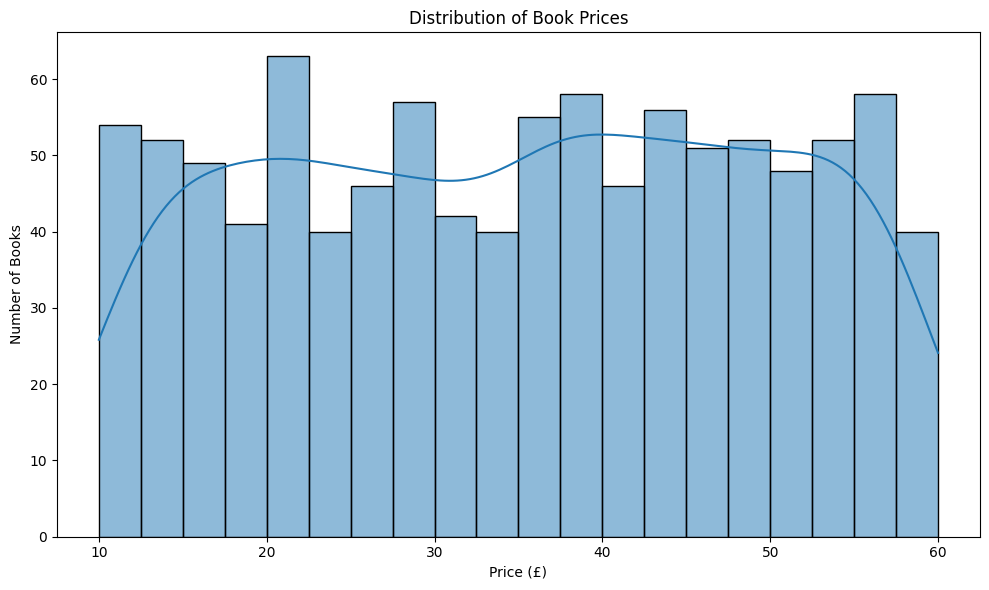

Average Price: 35.07
Minimum Price: 10.0
Maximum Price: 59.99
Median Price: 35.98


In [ ]:

#  Univariate Analysis - Price Distribution

plt.figure(figsize=(10, 6))

sns.histplot(data=clean_df, x="Price", bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("Visualizations/graph1.png", bbox_inches="tight")
plt.show()

print("Average Price:", round(clean_df["Price"].mean(), 2))
print("Minimum Price:", round(clean_df["Price"].min(), 2))
print("Maximum Price:", round(clean_df["Price"].max(), 2))
print("Median Price:", round(clean_df["Price"].median(), 2))


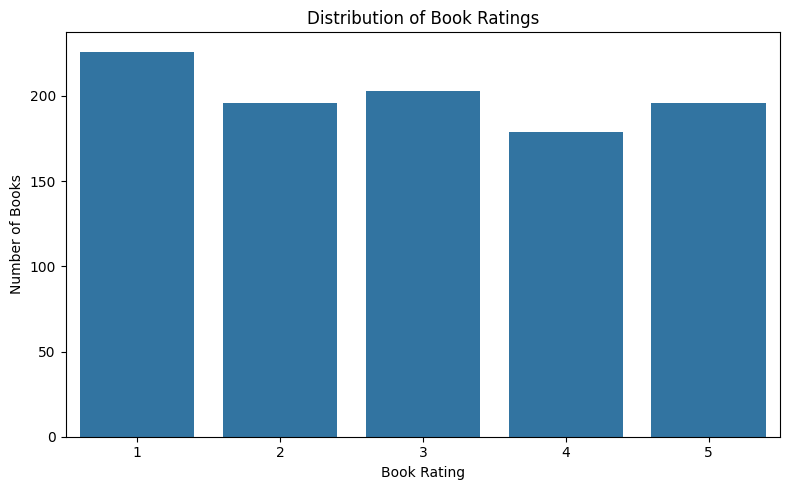

Rating Counts:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


In [ ]:
#  Univariate Analysis - Book Ratings

plt.figure(figsize=(8, 5))

sns.countplot(data=clean_df, x="Rating")

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("Visualizations/graph2.png", bbox_inches="tight")
plt.show()

print("Rating Counts:")
print(clean_df["Rating"].value_counts().sort_index())


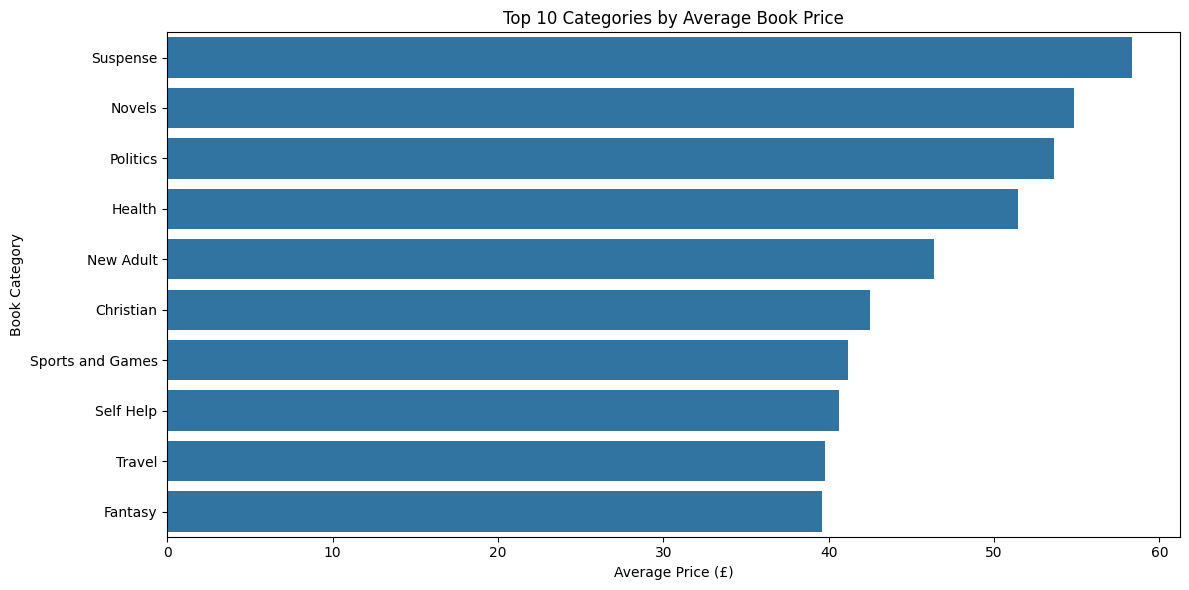

Top 10 Categories by Average Price:
Category
Suspense            58.33
Novels              54.81
Politics            53.61
Health              51.45
New Adult           46.38
Christian           42.50
Sports and Games    41.17
Self Help           40.62
Travel              39.79
Fantasy             39.59
Name: Price, dtype: float64


In [ ]:
# Bivariate Analysis - Category-wise Average Price

category_price = (
    clean_df.groupby("Category", observed=True)["Price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(x=category_price.values, y=category_price.index)

plt.title("Top 10 Categories by Average Book Price")
plt.xlabel("Average Price (£)")
plt.ylabel("Book Category")

plt.tight_layout()
plt.savefig("Visualizations/graph3.png", bbox_inches="tight")
plt.show()

print("Top 10 Categories by Average Price:")
print(category_price.round(2))

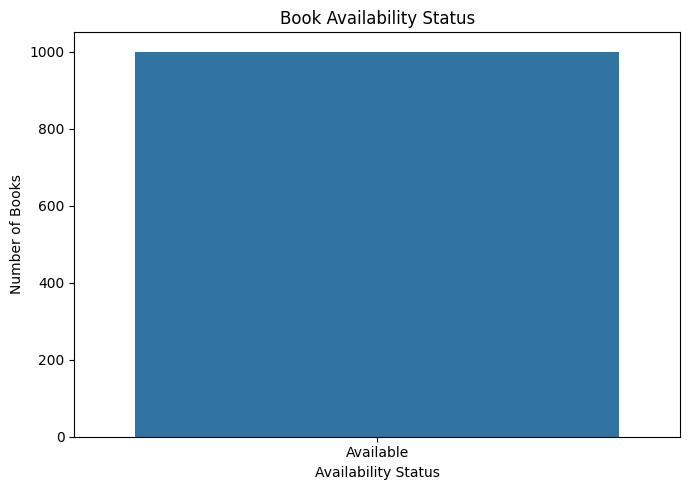

Availability Counts:
Availability_Status
Available    1000
Name: count, dtype: int64


In [ ]:
#  Univariate Analysis - Book Availability

availability_counts = clean_df["Availability_Status"].value_counts()

plt.figure(figsize=(7, 5))

sns.countplot(data=clean_df, x="Availability_Status")

plt.title("Book Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("Visualizations/graph4.png", bbox_inches="tight")
plt.show()

print("Availability Counts:")
print(availability_counts)

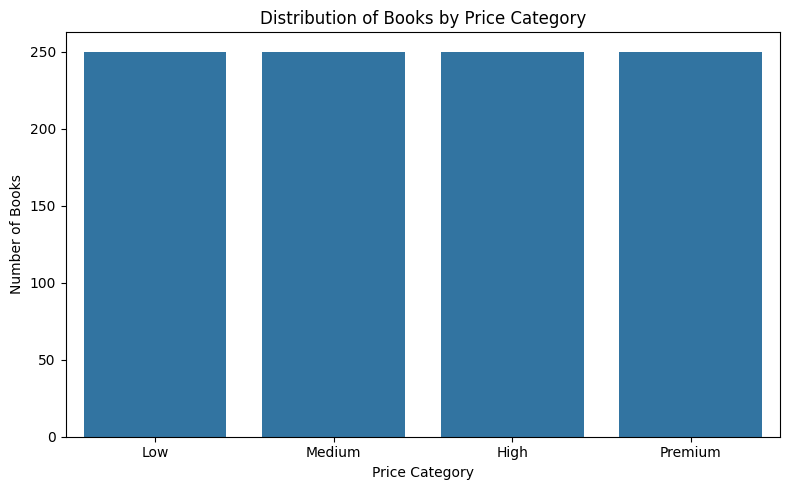

Price Category Counts:
Price_Category
Low        250
Medium     250
High       250
Premium    250
Name: count, dtype: int64


In [ ]:
# Univariate Analysis - Price Categories

plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="Price_Category",
    order=["Low", "Medium", "High", "Premium"]
)

plt.title("Distribution of Books by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("Visualizations/graph5.png", bbox_inches="tight")
plt.show()

print("Price Category Counts:")
print(
    clean_df["Price_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Premium"])
)

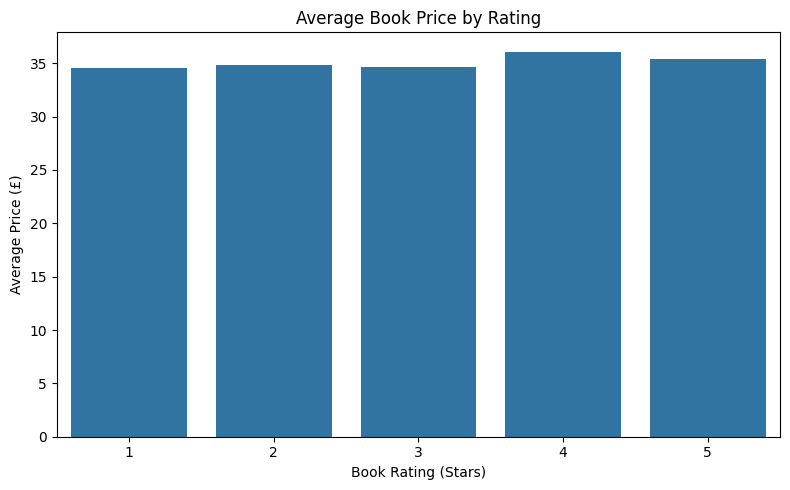

Average Price by Rating:
Rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: Price, dtype: float64


In [ ]:
#  Bivariate Analysis - Average Price by Rating

rating_price = clean_df.groupby("Rating")["Price"].mean()

plt.figure(figsize=(8, 5))

sns.barplot(x=rating_price.index, y=rating_price.values)

plt.title("Average Book Price by Rating")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Average Price (£)")

plt.tight_layout()
plt.savefig("Visualizations/graph6.png", bbox_inches="tight")
plt.show()

print("Average Price by Rating:")
print(rating_price.round(2))

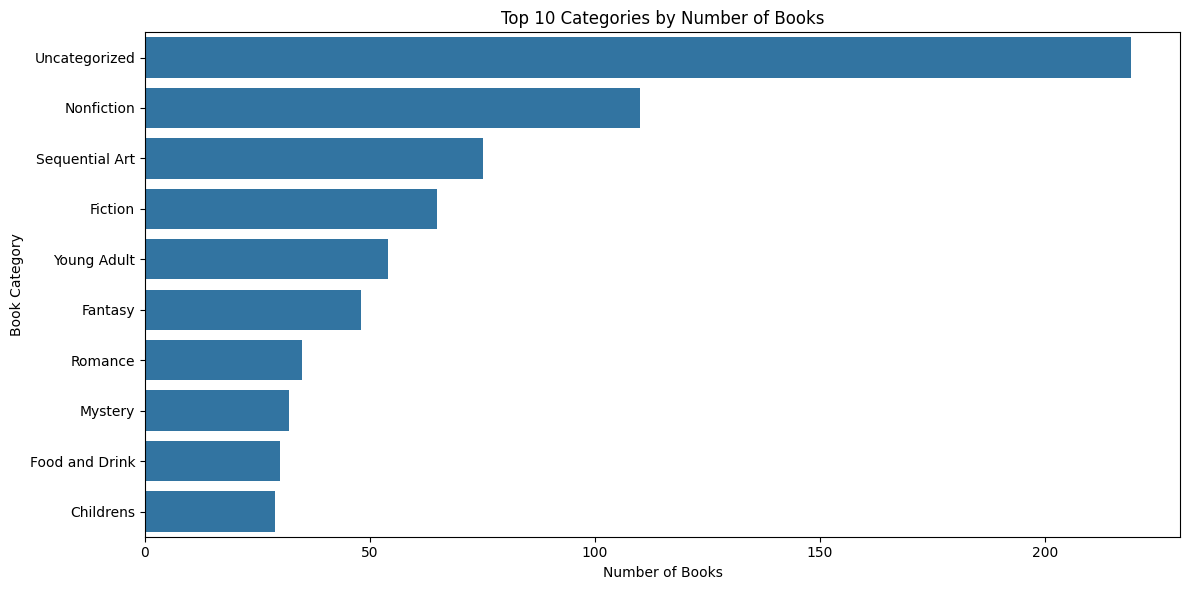

Top 10 Categories by Book Count:
Category
Uncategorized     219
Nonfiction        110
Sequential Art     75
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Childrens          29
Name: count, dtype: int64


In [ ]:
# Univariate Analysis - Top 10 Categories by Book Count

top_categories = clean_df["Category"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 10 Categories by Number of Books")
plt.xlabel("Number of Books")
plt.ylabel("Book Category")

plt.tight_layout()
plt.savefig("Visualizations/graph7.png", bbox_inches="tight")
plt.show()

print("Top 10 Categories by Book Count:")
print(top_categories)

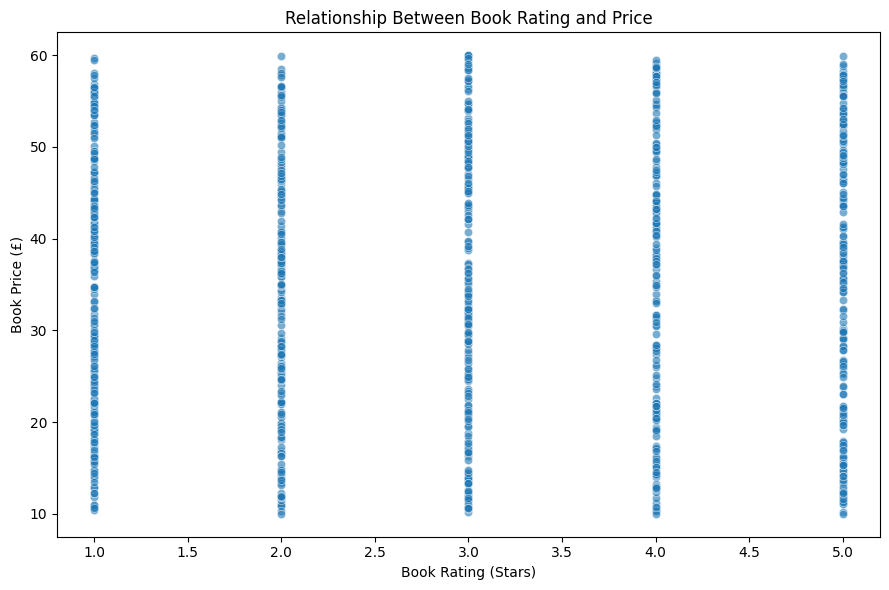

Correlation between Price and Rating:
0.028


In [ ]:
#  Multivariate Analysis - Price vs Rating

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=clean_df,
    x="Rating",
    y="Price",
    alpha=0.6
)

plt.title("Relationship Between Book Rating and Price")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Book Price (£)")

plt.tight_layout()
plt.savefig("Visualizations/graph8.png", bbox_inches="tight")
plt.show()

print("Correlation between Price and Rating:")
print(round(clean_df["Price"].corr(clean_df["Rating"]), 3))

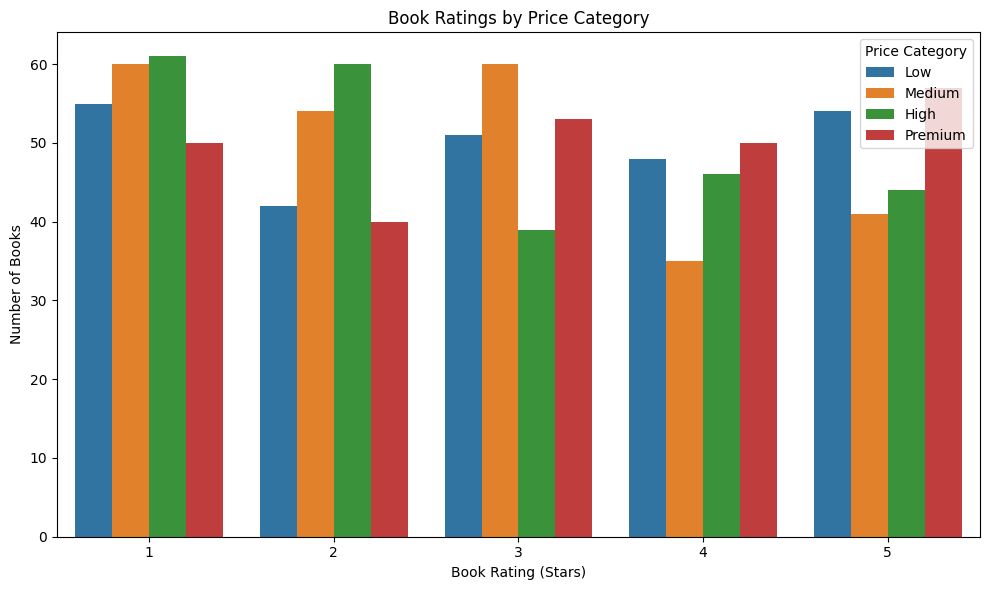

Rating and Price Category Summary:
Price_Category  Low  Medium  High  Premium
Rating                                    
1                55      60    61       50
2                42      54    60       40
3                51      60    39       53
4                48      35    46       50
5                54      41    44       57


In [ ]:
#  Multivariate Analysis - Rating and Price Category

plt.figure(figsize=(10, 6))

sns.countplot(
    data=clean_df,
    x="Rating",
    hue="Price_Category",
    hue_order=["Low", "Medium", "High", "Premium"]
)

plt.title("Book Ratings by Price Category")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Number of Books")
plt.legend(title="Price Category")

plt.tight_layout()
plt.show()

print("Rating and Price Category Summary:")
print(
    pd.crosstab(
        clean_df["Rating"],
        clean_df["Price_Category"]
    )
)

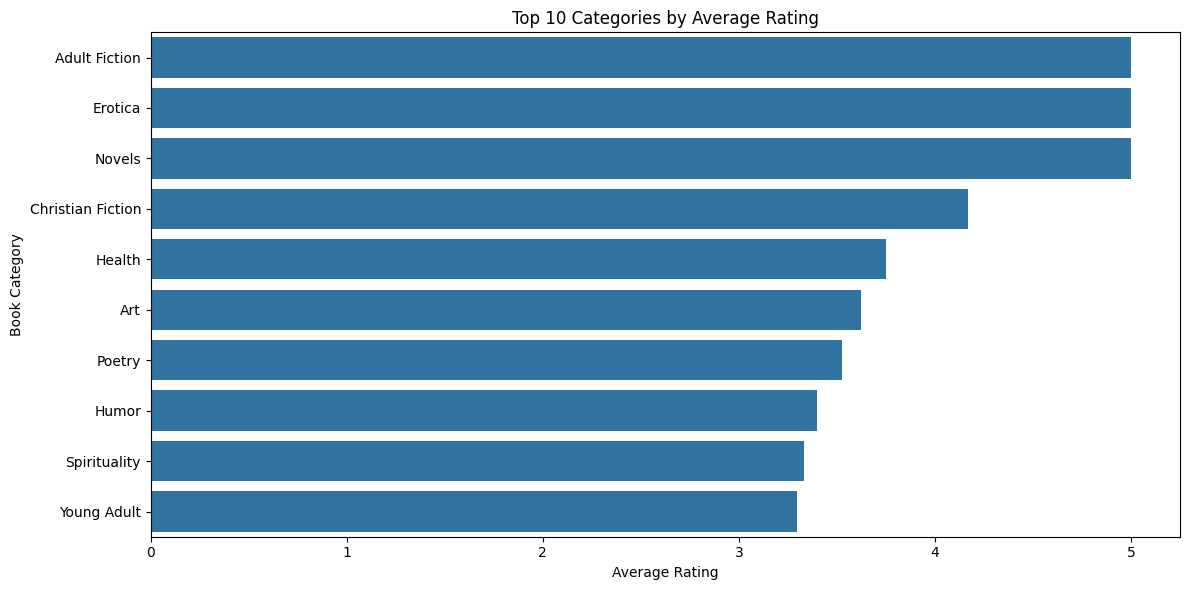

Top 10 Categories by Average Rating:
Category
Adult Fiction        5.00
Erotica              5.00
Novels               5.00
Christian Fiction    4.17
Health               3.75
Art                  3.62
Poetry               3.53
Humor                3.40
Spirituality         3.33
Young Adult          3.30
Name: Rating, dtype: float64


In [ ]:
#  Category-wise Average Rating

category_rating = (
    clean_df.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_rating.values,
    y=category_rating.index
)

plt.title("Top 10 Categories by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Book Category")

plt.tight_layout()
plt.show()

print("Top 10 Categories by Average Rating:")
print(category_rating.round(2))

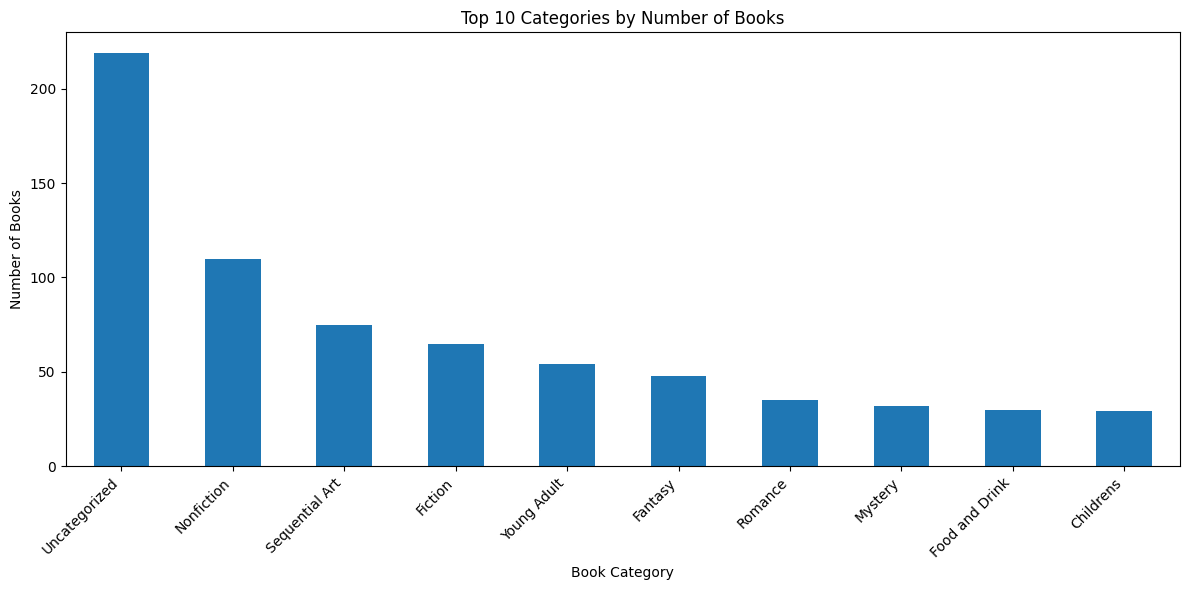

Books Count by Category:
Category
Uncategorized     219
Nonfiction        110
Sequential Art     75
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Childrens          29
Name: count, dtype: int64


In [ ]:
#  Books Count by Category

category_counts = clean_df["Category"].value_counts().head(10)

category_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Categories by Number of Books")
plt.xlabel("Book Category")
plt.ylabel("Number of Books")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Books Count by Category:")
print(category_counts)

In [ ]:
scraped_df["Category"].value_counts().head(15)

,count
Category,
Default,152
Nonfiction,110
Sequential Art,75
Add a comment,67
Fiction,65
Young Adult,54
Fantasy,48
Romance,35
Mystery,32


In [ ]:
#  Business Questions and Answers

print("BUSINESS QUESTIONS AND ANSWERS")
print("=" * 50)

# Q1: How many books are in the dataset?
print("\nQ1. How many books are in the dataset?")
print("Answer:", len(clean_df))

# Q2: What is the average book price?
print("\nQ2. What is the average book price?")
print("Answer: £", round(clean_df["Price"].mean(), 2))

# Q3: What is the minimum book price?
print("\nQ3. What is the minimum book price?")
print("Answer: £", round(clean_df["Price"].min(), 2))

# Q4: What is the maximum book price?
print("\nQ4. What is the maximum book price?")
print("Answer: £", round(clean_df["Price"].max(), 2))

# Q5: Which rating occurs most frequently?
print("\nQ5. Which rating occurs most frequently?")
print("Answer:", clean_df["Rating"].mode()[0], "stars")

# Q6: Which category has the most books?
print("\nQ6. Which category has the most books?")
print("Answer:", clean_df["Category"].value_counts().idxmax())

# Q7: Which category has the highest average price?
print("\nQ7. Which category has the highest average price?")
print(
    "Answer:",
    clean_df.groupby("Category")["Price"].mean().idxmax(),
    "- £",
    round(clean_df.groupby("Category")["Price"].mean().max(), 2)
)

# Q8: What is the most common price category?
print("\nQ8. What is the most common price category?")
print("Answer:", clean_df["Price_Category"].mode()[0])

# Q9: What is the correlation between price and rating?
print("\nQ9. What is the correlation between price and rating?")
print("Answer:", round(clean_df["Price"].corr(clean_df["Rating"]), 3))

# Q10: How many books are marked as available?
print("\nQ10. How many books are marked as available?")
print(
    "Answer:",
    (clean_df["Availability_Status"] == "Available").sum()
)

BUSINESS QUESTIONS AND ANSWERS

Q1. How many books are in the dataset?
Answer: 1000

Q2. What is the average book price?
Answer: £ 35.07

Q3. What is the minimum book price?
Answer: £ 10.0

Q4. What is the maximum book price?
Answer: £ 59.99

Q5. Which rating occurs most frequently?
Answer: 1 stars

Q6. Which category has the most books?
Answer: Uncategorized

Q7. Which category has the highest average price?
Answer: Suspense - £ 58.33

Q8. What is the most common price category?
Answer: Low

Q9. What is the correlation between price and rating?
Answer: 0.028

Q10. How many books are marked as available?
Answer: 1000


In [ ]:
#  Key Business Insights

print("KEY BUSINESS INSIGHTS")
print("=" * 60)

# Insight 1: Average book price
print("\n1. Average Book Price")
print(f"Average price is £{clean_df['Price'].mean():.2f}.")

# Insight 2: Price range
print("\n2. Book Price Range")
print(
    f"Prices range from £{clean_df['Price'].min():.2f} "
    f"to £{clean_df['Price'].max():.2f}."
)

# Insight 3: Most common rating
print("\n3. Most Common Rating")
print(
    f"{clean_df['Rating'].value_counts().idxmax()}-star rating "
    "is the most common."
)

# Insight 4: Largest category
print("\n4. Largest Book Category")
print(
    f"{clean_df['Category'].value_counts().idxmax()} "
    "has the highest number of books."
)

# Insight 5: Highest average price category
print("\n5. Highest Average Price Category")
category_avg_price = clean_df.groupby("Category")["Price"].mean()
print(
    f"{category_avg_price.idxmax()} has the highest average price "
    f"of £{category_avg_price.max():.2f}."
)

# Insight 6: Price category distribution
print("\n6. Price Category Distribution")
print(clean_df["Price_Category"].value_counts())

# Insight 7: Price and rating relationship
print("\n7. Price and Rating Relationship")
correlation = clean_df["Price"].corr(clean_df["Rating"])
print(f"Correlation is {correlation:.3f}, indicating almost no linear relationship.")

# Insight 8: Availability
print("\n8. Book Availability")
available_count = (
    clean_df["Availability_Status"] == "Available"
).sum()
print(f"{available_count} books are marked as available in the dataset.")

KEY BUSINESS INSIGHTS

1. Average Book Price
Average price is £35.07.

2. Book Price Range
Prices range from £10.00 to £59.99.

3. Most Common Rating
1-star rating is the most common.

4. Largest Book Category
Uncategorized has the highest number of books.

5. Highest Average Price Category
Suspense has the highest average price of £58.33.

6. Price Category Distribution
Price_Category
Low        250
Medium     250
High       250
Premium    250
Name: count, dtype: int64

7. Price and Rating Relationship
Correlation is 0.028, indicating almost no linear relationship.

8. Book Availability
1000 books are marked as available in the dataset.


In [ ]:
#  Actionable Business Recommendations

print("BUSINESS RECOMMENDATIONS")
print("=" * 60)

recommendations = [
    "1. Pricing Strategy: Review book prices across categories to identify suitable pricing opportunities.",
    "2. Customer Satisfaction: Investigate why 1-star ratings are the most common and identify areas for improvement.",
    "3. Category Management: Review book categories with fewer listings to identify opportunities to expand the catalogue.",
    "4. Inventory Management: Monitor stock availability regularly to reduce the risk of books becoming unavailable.",
    "5. Rating-Based Decisions: Use customer ratings along with price and other factors instead of relying on price alone."
]

for recommendation in recommendations:
    print("\n" + recommendation)

BUSINESS RECOMMENDATIONS

1. Pricing Strategy: Review book prices across categories to identify suitable pricing opportunities.

2. Customer Satisfaction: Investigate why 1-star ratings are the most common and identify areas for improvement.

3. Category Management: Review book categories with fewer listings to identify opportunities to expand the catalogue.

4. Inventory Management: Monitor stock availability regularly to reduce the risk of books becoming unavailable.

5. Rating-Based Decisions: Use customer ratings along with price and other factors instead of relying on price alone.


In [ ]:

#  Save Scraped and Cleaned Datasets

scraped_df.to_csv("books_scraped.csv", index=False)
clean_df.to_csv("books_cleaned.csv", index=False)

print("CSV files saved successfully!")
print("1. books_scraped.csv")
print("2. books_cleaned.csv")


CSV files saved successfully!
1. books_scraped.csv
2. books_cleaned.csv
